In [1]:
%pip install --upgrade pip setuptools wheel
%pip install "pandas>=3.0" numpy matplotlib
%pip install sqlalchemy psycopg2-binary
%pip install wrds --no-deps

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("walmart.csv")
data.head()

,costat,curcd,datafmt,indfmt,consol,sic,datadate,gvkey,conm,tic,fyear,at,ceq,ceql,gdwl,intan,aqc,csho,prcc_f
0,A,USD,STD,INDL,C,5080,2019-05-31,1004,AAR CORP,AIR,2018,1517.2,905.9,905.9,116.2,145.6,2.3,34.788,30.09
1,A,USD,STD,INDL,C,5080,2020-05-31,1004,AAR CORP,AIR,2019,2079.0,902.6,902.6,115.7,125.8,0.0,35.097,20.17
2,A,USD,STD,INDL,C,5080,2021-05-31,1004,AAR CORP,AIR,2020,1539.7,974.4,974.4,119.3,148.8,0.0,35.375,41.75
3,A,USD,STD,INDL,C,5080,2022-05-31,1004,AAR CORP,AIR,2021,1573.9,1034.5,1034.5,116.4,141.9,0.0,35.391,48.22
4,A,USD,STD,INDL,C,5080,2023-05-31,1004,AAR CORP,AIR,2022,1833.1,1099.1,1099.1,175.8,279.1,103.3,34.916,50.11


In [9]:
data["sic"] = data["sic"].astype(str)

industry = data[data["sic"].str[:2] == "53"].copy()
industry["market_cap"] = industry["prcc_f"] * industry["csho"] #Market Cap = Share Price * Sharesutstanding

latest_year = industry[industry["tic"] == "WMT"]["fyear"].max()
print(latest_year)
latest = industry[industry["fyear"] == latest_year].copy()
latest = latest.dropna(subset=["market_cap"])
latest["market_cap"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
)

2025


count        16.000000
mean     102399.026839
std      247419.035962
min        1956.640000
1%         2157.816394
25%        6482.803425
50%       11283.911140
75%       48332.264850
99%      869729.810026
max      949426.660000
Name: market_cap, dtype: float64

In [10]:
walmart = latest[latest["tic"] == "WMT"]
wmt_market_cap = walmart["market_cap"].iloc[0] #iloc takes the first value of the market cap column
print("Walmart's Market Capitalisation:", wmt_market_cap)

Walmart's Market Capitalisation: 949426.66


In [11]:
#find the difference in market caps
#for every company in 'latest', company market cap - walmart market cap
# abs makes the result positive
latest["difference"] = abs(
    latest["market_cap"] - wmt_market_cap
)
not_walmart=latest[latest["tic"] != "WMT"] #removes walmart
sorted_companies=not_walmart.sort_values("difference") #sorts company market cap difference in ascending order
peers = sorted_companies.head(5) #keeps first 5 companies (closest peers)
print(peers[["conm", "tic", "market_cap", "difference"]])


                             conm    tic     market_cap     difference
27032       COSTCO WHOLESALE CORP   COST  418114.326840  531312.333160
66761  WAL MART DE MEXICO S A B D  WMMVY   53868.692592  895557.967408
87903               DOLLARAMA INC  DLMAF   50045.955000  899380.705000
1825                  TARGET CORP    TGT   47761.034800  901665.625200
1948          DOLLAR GENERAL CORP     DG   31586.441460  917840.218540


['WMT', 'COST', 'WMMVY', 'DLMAF', 'TGT', 'DG']
[2021, 2022, 2023, 2024, 2025]
tic     COST     DG  DLMAF    TGT  WMMVY    WMT
fyear                                          
2021   0.087  0.131 -0.003  0.123  0.139  0.216
2022   0.089  0.108  0.001  0.142  0.168  0.198
2023   0.103  0.233  0.014  0.209  0.160  0.189
2024   0.060  0.474  0.031  0.233  0.243  0.116
2025   0.070  0.269  0.029  0.338  0.243  0.105


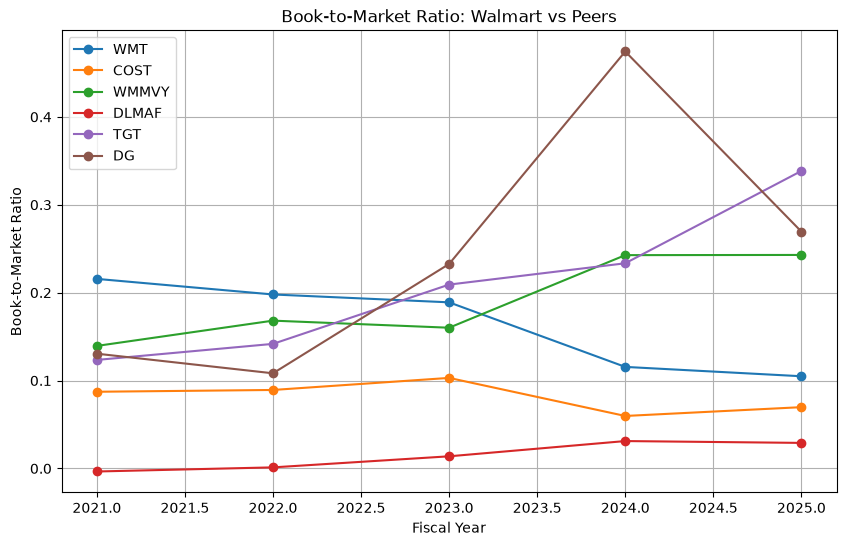

In [12]:
#calculate book-to-market=book value of equity(common equity)/market value of equity(market cap)
industry["book_to_market"] = (
    industry["ceq"] / industry["market_cap"]
)
companies = ["WMT"] + peers["tic"].tolist()
print(companies)
comparison = industry[industry["tic"].isin(companies)].copy()
years = list(range(int(latest_year) - 4, int(latest_year) + 1))

print(years)
comparison = comparison[comparison["fyear"].isin(years)].copy()

btm_table = comparison.pivot_table(
    index="fyear",
    columns="tic",
    values="book_to_market"
)

print(btm_table.round(3))

plt.figure(figsize=(10, 6))

for company in companies:
    company_data = comparison[comparison["tic"] == company]
    company_data = company_data.sort_values("fyear")

    plt.plot(
        company_data["fyear"],
        company_data["book_to_market"],
        marker="o",
        label=company
    )

plt.xlabel("Fiscal Year")
plt.ylabel("Book-to-Market Ratio")
plt.title("Book-to-Market Ratio: Walmart vs Peers")
plt.legend()
plt.grid()

plt.show()


In [13]:
btm_change = btm_table.iloc[-1] - btm_table.iloc[0]

print(btm_change.round(3)) #2025 B/M - 2021 B/M

comparison = industry[industry["tic"].isin(companies)].copy()

years = list(range(int(latest_year) - 4, int(latest_year) + 1))

comparison = comparison[
    comparison["fyear"].isin(years)
].copy()

btm_table = comparison.pivot_table(
    index="fyear",
    columns="tic",
    values="book_to_market"
)

print(btm_table.round(3))

btm_change = btm_table.iloc[-1] - btm_table.iloc[0]

print(btm_change.round(3))

tic
COST    -0.018
DG       0.139
DLMAF    0.033
TGT      0.215
WMMVY    0.103
WMT     -0.111
dtype: float64
tic     COST     DG  DLMAF    TGT  WMMVY    WMT
fyear                                          
2021   0.087  0.131 -0.003  0.123  0.139  0.216
2022   0.089  0.108  0.001  0.142  0.168  0.198
2023   0.103  0.233  0.014  0.209  0.160  0.189
2024   0.060  0.474  0.031  0.233  0.243  0.116
2025   0.070  0.269  0.029  0.338  0.243  0.105
tic
COST    -0.018
DG       0.139
DLMAF    0.033
TGT      0.215
WMMVY    0.103
WMT     -0.111
dtype: float64


Walmart's book-to-market ratio fell from 0.216 in 2021 to 0.105 in 2025, representing a decrease of 0.111 over the five-year period.
This contrasts with most of its selected peers, whose book-to-market ratios increased over the same period. Costco was the only other peer to experience a decline, although its decrease was much smaller at 0.018.
By 2025, Walmart's book-to-market ratio of 0.105 was lower than those of Dollar General, Target, and Wal-Mart de México, but higher than Costco and Dollarama.

In [ ]:
# Load the extra balance-sheet variables downloaded from WRDS
extra = pd.read_csv("walmart_extra.csv")
extra.columns = extra.columns.str.lower()      

# Keep the same Compustat screens as walmart.csv (
for col, value in {"indfmt": "INDL", "datafmt": "STD", "consol": "C"}.items():
    if col in extra.columns:
        extra = extra[extra[col] == value]

extra = extra[["gvkey", "datadate", "ppent", "invt", "che", "rect"]].copy()
extra["datadate"] = pd.to_datetime(extra["datadate"])
print("Rows in walmart_extra.csv:", len(extra))
print("Duplicate firm-years in extra file:", extra.duplicated(["gvkey", "datadate"]).sum())

Rows in walmart_extra.csv: 35
Duplicate firm-years in extra file: 0


In [ ]:

comparison["datadate"] = pd.to_datetime(comparison["datadate"])

rows_before = len(comparison)
assets = comparison.merge(extra, on=["gvkey", "datadate"],
                          how="left", validate="one_to_one")

# Sample checks: the merge must not add or drop rows, and must not create duplicates
print("Rows before merge:", rows_before, "| after merge:", len(assets))
print("Duplicate firm-years:", assets.duplicated(["tic", "fyear"]).sum())
print("Missing values per new variable:")
print(assets[["ppent", "invt", "che", "rect"]].isna().sum())

# Cross-check against Walmart's 10-K (year ended 31 Jan 2026): total assets $284,668m
print("WMT total assets, fyear", max(years), ":",
      assets.loc[(assets["tic"] == "WMT") & (assets["fyear"] == max(years)), "at"].iloc[0])

Rows before merge: 30 | after merge: 30
Duplicate firm-years: 0
Missing values per new variable:
ppent    0
invt     0
che      0
rect     5
dtype: int64
WMT total assets, fyear 2025 : 284668.0


In [16]:
# Each asset category as a share of total assets.
# Notes on Compustat definitions:
#  - 'intan' INCLUDES goodwill, so other intangibles = intan - gdwl
#  - 'ppent' includes lease right-of-use assets (e.g. Walmart 2025: 136,083 + 14,750 + 6,123 = 156,956 in the 10-K)
#  - Dollar General's receivables are missing (not reported separately) from fiscal 2022, so we treat them as 0
#  - 'Other' is what is left: prepaid expenses, other long-term assets and equity investments
assets["rect"] = assets["rect"].fillna(0)
assets["PP&E"] = assets["ppent"] / assets["at"]
assets["Inventory"] = assets["invt"] / assets["at"]
assets["Cash"] = assets["che"] / assets["at"]
assets["Receivables"] = assets["rect"] / assets["at"]
assets["Goodwill"] = assets["gdwl"] / assets["at"]
assets["Other intangibles"] = (assets["intan"] - assets["gdwl"]) / assets["at"]

categories = ["PP&E", "Inventory", "Cash", "Receivables", "Goodwill", "Other intangibles"]
assets["Other"] = 1 - assets[categories].sum(axis=1)
categories = categories + ["Other"]

latest_assets = assets[assets["fyear"] == max(years)].set_index("tic")[categories]
latest_assets = latest_assets.loc[companies]          # keep Walmart first
print("Asset composition, fiscal year", max(years), "(% of total assets)")
print((latest_assets * 100).round(1))

Asset composition, fiscal year 2025 (% of total assets)
       PP&E  Inventory  Cash  Receivables  Goodwill  Other intangibles  Other
tic                                                                          
WMT    55.1       20.7   3.8          3.9      10.1                1.5    4.9
COST   46.9       23.5  19.8          4.2       1.3                0.0    4.4
WMMVY  53.1       21.7   5.8          5.4       7.7                1.0    5.5
DLMAF  48.4       14.6   4.4          0.5      10.6                2.4   19.2
TGT    63.0       20.7   9.2          3.0       1.1                0.0    3.0
DG     56.4       20.4   3.7          0.0      14.0                3.9    1.6


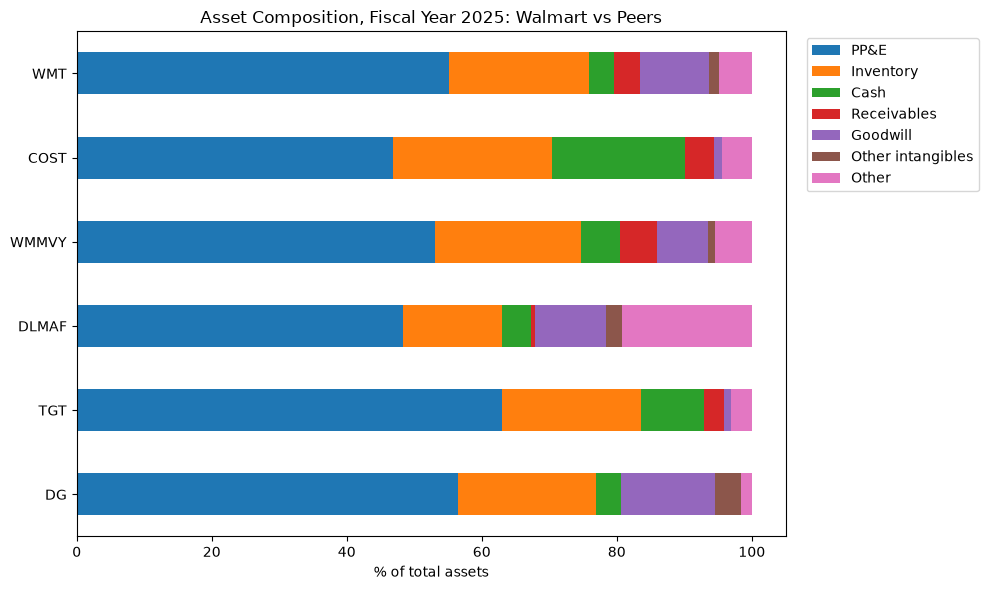

In [17]:
# Stacked bar chart: what each company's assets are made of in the latest year
ax = (latest_assets * 100).plot(kind="barh", stacked=True, figsize=(10, 6))
ax.invert_yaxis()                                   # Walmart at the top
ax.set_xlabel("% of total assets")
ax.set_ylabel("")
ax.set_title(f"Asset Composition, Fiscal Year {max(years)}: Walmart vs Peers")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

tic     WMT  COST  WMMVY  DLMAF  TGT    DG
fyear                                     
2021   11.8   1.7    9.1   17.9  1.2  16.5
2022   11.6   1.5    8.5   15.1  1.2  14.9
2023   11.1   1.4    7.9   13.8  1.1  14.1
2024   11.0   1.4    8.6   11.2  1.1  13.9
2025   10.1   1.3    7.7   10.6  1.1  14.0


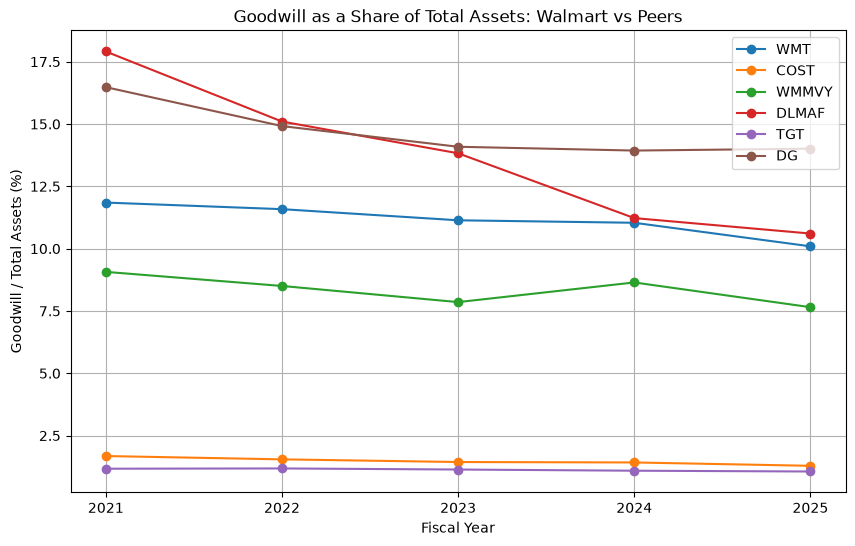

In [18]:
# Goodwill as a share of total assets over the last five years
gw_table = assets.pivot_table(index="fyear", columns="tic", values="Goodwill")[companies]
print((gw_table * 100).round(1))

plt.figure(figsize=(10, 6))
for company in companies:
    plt.plot(gw_table.index, gw_table[company] * 100, marker="o", label=company)
plt.xlabel("Fiscal Year")
plt.ylabel("Goodwill / Total Assets (%)")
plt.title("Goodwill as a Share of Total Assets: Walmart vs Peers")
plt.xticks(years)
plt.legend()
plt.grid()
plt.show()

Change 2021-2025 (millions, reporting currency)
       change_total_assets  change_PP&E  change_goodwill  acquisitions_total  acquisitions_%_of_assets
tic                                                                                                   
WMT                39808.0      44332.0           -279.0              3057.0                       1.1
COST               17831.0       8740.0             -2.0                 0.0                       0.0
WMMVY               8271.8       4828.4            360.5                10.0                       0.0
DLMAF               3494.8       1413.6             73.9               181.8                       2.4
TGT                 5679.0       6715.0              0.0                 0.0                       0.0
DG                  4636.4       3032.0              0.0                 0.0                       0.0


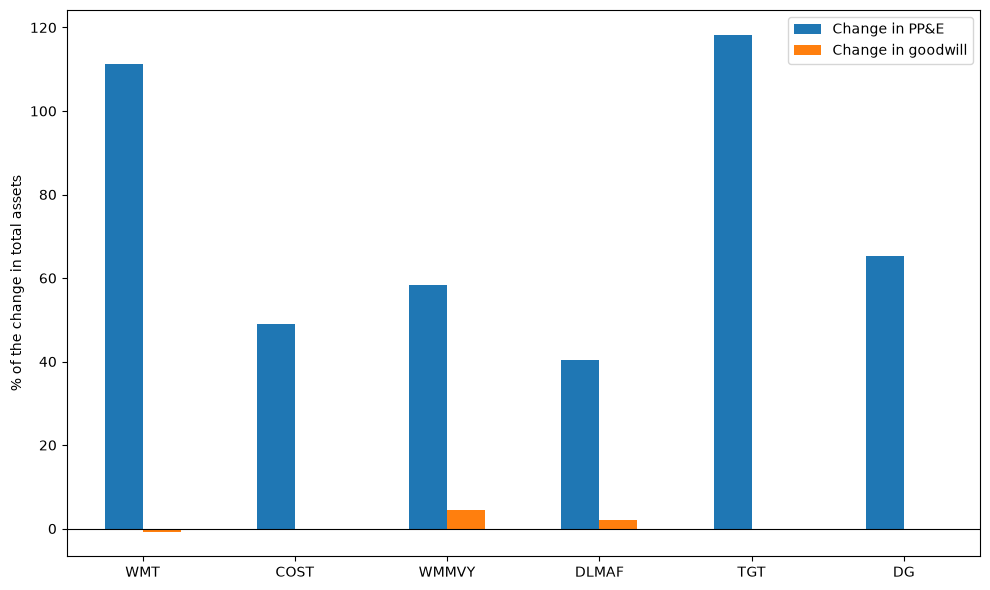

In [22]:
# Where did asset growth come from? Change from the first to the last year of the window
first = assets[assets["fyear"] == min(years)].set_index("tic")
last = assets[assets["fyear"] == max(years)].set_index("tic")

growth = pd.DataFrame({
    "change_total_assets": last["at"] - first["at"],
    "change_PP&E": last["ppent"] - first["ppent"],
    "change_goodwill": last["gdwl"] - first["gdwl"],
}).loc[companies]

# Total acquisition spending over the five years (aqc, from walmart.csv), and as % of latest total assets
growth["acquisitions_total"] = assets.groupby("tic")["aqc"].sum().loc[companies]
growth["acquisitions_%_of_assets"] = 100 * growth["acquisitions_total"] / last["at"].loc[companies]

print(f"Change {min(years)}-{max(years)} (millions, reporting currency)")
print(growth.round(1).to_string())

# Chart: change in PP&E vs change in goodwill, as % of the change in total assets
share = growth[["change_PP&E", "change_goodwill"]].div(growth["change_total_assets"], axis=0) * 100
ax = share.plot(kind="bar", figsize=(10, 6))
ax.set_ylabel("% of the change in total assets")
ax.set_xlabel("")
ax.set_title(f"")
ax.legend(["Change in PP&E", "Change in goodwill"])
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()